[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nattaponm/Teach_stormTracks_KKN_May2024_HID_doppler/blob/main/prep/PS_sounding_hid_profiles.ipynb)


# PS — Sounding สำหรับ HID: ดาวน์โหลด, QC และโปรไฟล์อุณหภูมิรายวัน

**สำหรับผู้ดูแลข้อมูล** — รันก่อน P2 (ไม่ต้องใช้ข้อมูลเรดาร์ จึงรันเมื่อไรก็ได้)

การจำแนก HID และการแก้การลดทอน Z-PHI ใช้อุณหภูมิทุก gate ซึ่ง `polar_tools.add_temperature` หาด้วย `np.interp` จาก sounding **เหนือยอด sounding จะได้อุณหภูมิของระดับบนสุดค้างไปทั้งคอลัมน์** ถ้า sounding สั้น เช่น 12 พ.ค. 2567 (สูงแค่ 1.1 km) ทุก gate จะอุ่นกว่า 20 °C และ HID จะไม่พบน้ำแข็งเลยโดยไม่มี error เตือน notebook นี้จึงสร้างโปรไฟล์ที่ครบ 0–20 km ทุกวัน พร้อมบอกว่ามาจากไหน

**ลำดับการเลือกโปรไฟล์ของแต่ละวัน**

| ลำดับ | ป้าย | เงื่อนไข |
|---|---|---|
| 1 | `own` | โคราช (48431) วันนั้น ผ่าน QC และสูงถึง ≥ 12 km (เหนือระดับ −40 °C) |
| 2 | `spliced` | โคราชวันนั้นผ่านระดับ 0 °C แล้วอย่างน้อย 1 km → ใช้ข้อมูลจริงถึงยอด แล้วต่อด้วย composite ทั้งเดือน |
| 3 | `ubon_own` / `ubon_spliced` | อุบลราชธานี (48407) วันเดียวกัน เมื่อโคราชใช้ไม่ได้ |
| 4 | `neighbor_mean(...)` | ค่าเฉลี่ยของวันก่อนและหลังที่ใกล้ที่สุด (จากข้อ 1–2) ภายใน ±3 วัน |
| 5 | `composite` | มัธยฐานทั้งเดือน |

การต่อเติม (splice) ที่ยอดสูง $z_t$:

$$T(z) = T_{\mathrm{comp}}(z) + \delta\,\max\!\left(0,\ 1-\frac{z-z_t}{2\ \mathrm{km}}\right),\qquad \delta = T_{\mathrm{own}}(z_t)-T_{\mathrm{comp}}(z_t)$$

**ทำไมต่อเติมได้:** บรรยากาศเขตร้อนชั้นกลาง-บนแปรผันน้อย ระดับ 0 °C เดือนพฤษภาคม 2567 มี IQR เพียง ~135 m ซึ่งเล็กกว่าความกว้างลำคลื่น (1.7 km ที่ระยะ 100 km) มาก

**แก้จากโค้ดดาวน์โหลดเดิม** (`00_download_Korat_sounding_MarMay2024`): (1) ลองแหล่ง BUFR และรอบ 12 UTC สำหรับวันที่ขาด/สั้น (2) ไม่ใช้ cache ที่สั้นซ้ำ (3) เพิ่ม QC เชิงฟิสิกส์ — เช่น 28 พ.ค. เหนือ 15.5 km อุณหภูมิเป็น +41 ถึง +49 °C ซึ่งเดิมไม่ถูกตัด (4) เพิ่มเกณฑ์ "ใช้ทำ HID ได้" รายวัน

| ผลลัพธ์ใน `data/sounding/` (ข้อมูลเปิดจาก U. Wyoming เก็บใน repo ได้) | เนื้อหา |
|---|---|
| `may2024_hid_profiles.nc` | อุณหภูมิ/จุดน้ำค้าง วัน × ความสูง 0–20 km ทุก 100 m + แหล่งที่มา |
| `may2024_hid_profile_summary.csv` | แหล่งที่มา ความสูงต่อเติม ระดับ 0/−10/−20/−40 °C รายวัน |
| `may2024_sounding_qc.csv`, `may2024_download_attempts.csv` | ผล QC และการดึงข้อมูลซ้ำ |
| `may2024_environment_daily.csv` | CAPE, DCAPE, PW, lapse rate, shear 0–1/0–6 km (เฉพาะ sounding ที่ครบ) |
| `may2024_levels_qc.csv` | ระดับข้อมูลทุกระดับหลัง QC (ใช้ซ้ำใน notebook อื่นได้) |

In [1]:
# @title ⚙️ เตรียมสภาพแวดล้อม (รันก่อนเสมอ)
import os, sys, subprocess
REPO = "Teach_stormTracks_KKN_May2024_HID_doppler"
if "google.colab" in sys.modules:
    if not os.path.isdir(f"/content/{REPO}"):
        subprocess.run(["git", "clone", "-q", "--depth", "1", f"https://github.com/nattaponm/{REPO}.git", f"/content/{REPO}"], check=True)
    else:
        subprocess.run(["git", "-C", f"/content/{REPO}", "pull", "-q"])
    os.chdir(f"/content/{REPO}")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt", "metpy", "beautifulsoup4"], check=True)
elif os.path.basename(os.getcwd()) in ("notebooks", "prep"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())
print("โฟลเดอร์ทำงาน:", os.getcwd(), "| CPU", os.cpu_count(), "core")

โฟลเดอร์ทำงาน: /content/Teach_stormTracks_KKN_May2024_HID_doppler | CPU 8 core


In [2]:
import json, time, shutil, warnings
from pathlib import Path
from functools import partial
from concurrent.futures import ProcessPoolExecutor
import multiprocessing as mproc
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
warnings.filterwarnings("ignore")

from utils.config import load_settings, repo_path
from utils import maps as M
s = load_settings()
M.setup_style()
OUT_ROOT = Path(os.environ.get("KKN_OUT_ROOT", s["radar_data"]["drive_derived_root"]))
N_WORKERS = os.cpu_count()
CTX = mproc.get_context("fork")

from utils import sounding as S
SND = repo_path("data", "sounding"); SND.mkdir(parents=True, exist_ok=True)
DAYS = pd.date_range(f"{s['project']['year_ce']}-{s['project']['month']:02d}-01", periods=31, freq="D")
TRY_DOWNLOAD = os.environ.get("KKN_TRY_DOWNLOAD", "1") == "1"   # "0" = ใช้เฉพาะไฟล์รวมของ repo sounding (ไม่ต่ออินเทอร์เน็ตไปที่ Wyoming)

## 1. ไฟล์รวม 00 UTC จาก repo Teaching_Sounding_SevereStorm_Korat และ QC

In [3]:
korat = S.load_base_dataset(s["sounding"]["base_dataset_url"], s["project"]["month"], s["project"]["year_ce"])
for d, df in korat.items():
    df.attrs["source"] = "48431 00Z FM35 (base dataset)"
rows = []
for d in DAYS:
    if d in korat:
        q, info = S.qc_profile(korat[d])
        g = S.to_grid(q)
        rows.append({"day": d, "n_levels": info["n_raw"], "top_m": info["top_m"], "top_T": info["top_T"],
                     "quality": S.classify_quality(info, g["T"]), "flags": ";".join(info["flags"])})
    else:
        rows.append({"day": d, "quality": "missing"})
base_qc = pd.DataFrame(rows)
print(base_qc["quality"].value_counts().to_string())
base_qc[base_qc["quality"] != "full"]

quality
full          20
spliceable     5
missing        4
unusable       2


,day,n_levels,top_m,top_T,quality,flags
6,2024-05-07,20.0,6792.0,-9.5,spliceable,
7,2024-05-08,40.0,8195.0,-19.3,spliceable,
11,2024-05-12,4.0,1112.0,23.6,unusable,
14,2024-05-15,31.0,9905.0,-29.1,spliceable,
16,2024-05-17,NaN,NaN,NaN,missing,NaN
17,2024-05-18,6.0,3362.0,10.8,unusable,
20,2024-05-21,NaN,NaN,NaN,missing,NaN
21,2024-05-22,NaN,NaN,NaN,missing,NaN
22,2024-05-23,19.0,8556.0,-17.9,spliceable,
29,2024-05-30,NaN,NaN,NaN,missing,NaN


## 2. ลองดึงใหม่สำหรับวันที่ขาดหรือสั้น (โคราช: BUFR / 12 UTC) แล้วอุบลราชธานีเป็นทางสำรอง

archive ของ University of Wyoming เก็บข้อมูลบางวันจากหลายแหล่ง (`src=FM35` คือข้อความ TEMP, `src=BUFR`) โค้ดเดิมดึงเฉพาะ FM35 รอบ 00 UTC เซลล์นี้ลองทุกแบบที่ตั้งไว้ใน `config/settings.yaml` แล้ว **เลือกโปรไฟล์ที่คุณภาพดีที่สุด** (full > spliceable) ถ้าเครือข่ายขัดข้องจะบันทึกเป็น error แล้วทำงานต่อด้วยข้อมูลที่มี

In [4]:
rank = {"full": 3, "spliceable": 2, "unusable": 1, "missing": 0}
attempts, ubon = [], {}

def try_variants(station, day, variants):
    best, best_q = None, "missing"
    for hour, src in variants:
        t = day + pd.Timedelta(hours=int(hour))
        status, df, url, msg = S.fetch_sounding(station, t, src=src)
        q = "missing"
        if df is not None:
            qq, info = S.qc_profile(df)
            q = S.classify_quality(info, S.to_grid(qq)["T"]) if len(qq) > 1 else "unusable"
            df.attrs["source"] = f"{station} {int(hour):02d}Z {src}"
        attempts.append({"day": day, "station": station, "hour_utc": hour, "src": src, "status": status,
                         "quality": q, "message": msg, "url": url})
        if rank[q] > rank[best_q]:
            best, best_q = df, q
        if best_q == "full":
            break
    return best, best_q

if TRY_DOWNLOAD:
    for d in base_qc.loc[base_qc["quality"] != "full", "day"]:
        cur = base_qc.loc[base_qc["day"] == d, "quality"].iloc[0]
        df, q = try_variants(s["sounding"]["primary_station"], d, s["sounding"]["retry_variants"])
        if df is not None and rank[q] > rank[cur]:
            korat[d] = df; cur = q
            print(f"{d:%d %b}: โคราชได้โปรไฟล์ที่ดีขึ้น ({df.attrs['source']}, {q})")
        if cur in ("missing", "unusable"):
            df, q = try_variants(s["sounding"]["fallback_station"], d, s["sounding"]["fallback_variants"])
            if df is not None and q in ("full", "spliceable"):
                ubon[d] = df
                print(f"{d:%d %b}: ใช้อุบลราชธานี ({df.attrs['source']}, {q})")
att = pd.DataFrame(attempts)
if len(att):
    print(att.groupby(["station", "status"]).size().to_string())
    n_err = int((att["status"] == "error").sum())
    if n_err == len(att):
        print("⚠️ เชื่อมต่อ Wyoming ไม่ได้เลย — ใช้ไฟล์รวมเดิม + ค่าเฉลี่ยวันข้างเคียง (รันเซลล์นี้ใหม่ภายหลังได้)")
att.to_csv(SND / "may2024_download_attempts.csv", index=False)

30 May: ใช้อุบลราชธานี (48407 00Z FM35, full)
station  status    
48407    downloaded     1
         no_data       10
48431    no_data       33


## 3. โปรไฟล์อุณหภูมิรายวันสำหรับ HID

In [5]:
prof, summ, qc = S.build_daily_profiles(DAYS, korat, ubon)
summ.round(0)

,day,hid_profile_source,splice_height_m,z0C_m,zm10C_m,zm20C_m,zm40C_m,korat_quality,korat_top_m,korat_qc_flags
0,2024-05-01,own,NaN,5651.0,6898.0,8744.0,11160.0,full,22639.0,
1,2024-05-02,own,NaN,5379.0,7174.0,8735.0,11375.0,full,20720.0,
2,2024-05-03,own,NaN,5172.0,6880.0,8516.0,11304.0,full,25480.0,
3,2024-05-04,own,NaN,4831.0,6984.0,8483.0,11301.0,full,25837.0,
4,2024-05-05,own,NaN,5291.0,6776.0,8384.0,11175.0,full,26201.0,
5,2024-05-06,own,19800.0,5047.0,7109.0,8405.0,11155.0,full,19868.0,
6,2024-05-07,spliced,6700.0,5005.0,6948.0,8699.0,11340.0,spliceable,6792.0,
7,2024-05-08,spliced,8100.0,5203.0,6915.0,8407.0,11340.0,spliceable,8195.0,
8,2024-05-09,own,NaN,5064.0,6814.0,8644.0,11213.0,full,23881.0,
9,2024-05-10,own,NaN,5253.0,6971.0,8442.0,11199.0,full,23712.0,


บันทึกรูป → /content/Teach_stormTracks_KKN_May2024_HID_doppler/data/sounding/figures/ps_hid_profiles.png / .pdf


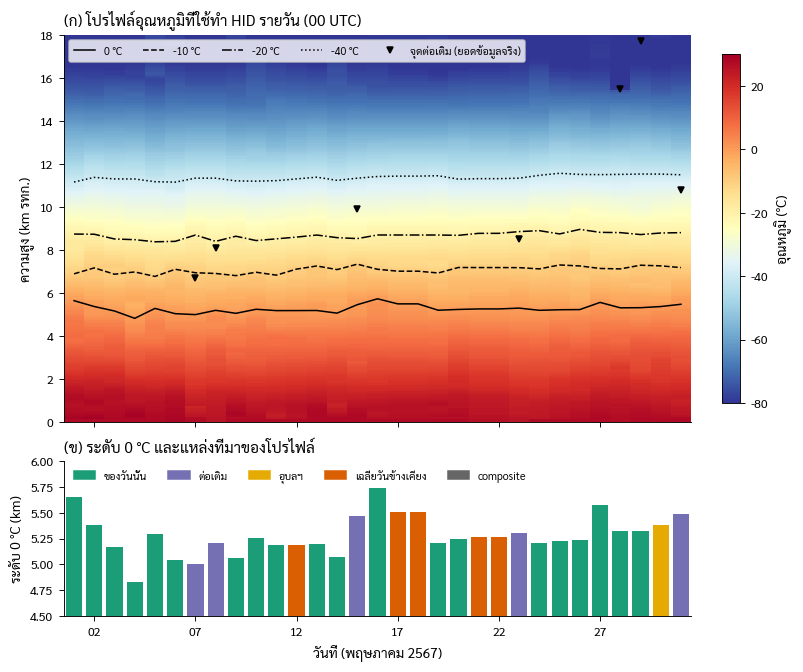

In [6]:
# รูป 1: โปรไฟล์รายวัน (ภาพตัดเวลา–ความสูง) + ระดับไอโซเทอร์ม + แหล่งที่มา
src_col = {"own": "#1b9e77", "spliced": "#7570b3", "ubon": "#e6ab02", "neighbor": "#d95f02", "composite": "#666666"}
def src_color(lbl):
    return next(c for k, c in src_col.items() if lbl.startswith(k))
fig, axs = plt.subplots(2, 1, figsize=(7.2, 6.0), sharex=True, gridspec_kw={"height_ratios": [3, 1.2]}, layout="constrained")
ax = axs[0]
T = prof["temperature"].values
X = mdates.date2num(pd.to_datetime(prof["day"].values))
pc = ax.pcolormesh(X, prof["height"].values / 1000, T.T, cmap="RdYlBu_r", vmin=-80, vmax=30, shading="nearest")
for lev, ls in [(0, "-"), (-10, "--"), (-20, "-."), (-40, ":")]:
    col = {0: "z0C_m", -10: "zm10C_m", -20: "zm20C_m", -40: "zm40C_m"}[lev]
    ax.plot(X, summ[col] / 1000, "k", ls=ls, lw=1, label=f"{lev} °C")
sp = summ["splice_height_m"] < 19000
ax.plot(X[sp], summ.loc[sp, "splice_height_m"] / 1000, "v", color="k", ms=4, label="จุดต่อเติม (ยอดข้อมูลจริง)")
ax.set_ylim(0, 18); ax.set_ylabel("ความสูง (km รทก.)")
ax.legend(loc="upper left", ncol=5, fontsize=7, frameon=True)
fig.colorbar(pc, ax=ax, label="อุณหภูมิ (°C)", shrink=0.9)
ax.set_title("(ก) โปรไฟล์อุณหภูมิที่ใช้ทำ HID รายวัน (00 UTC)", loc="left")
ax = axs[1]
ax.bar(X, summ["z0C_m"] / 1000, color=[src_color(v) for v in summ["hid_profile_source"]], width=0.8)
ax.set_ylim(4.5, 6.0); ax.set_ylabel("ระดับ 0 °C (km)")
from matplotlib.patches import Patch
ax.legend([Patch(color=c) for c in src_col.values()], ["ของวันนั้น", "ต่อเติม", "อุบลฯ", "เฉลี่ยวันข้างเคียง", "composite"],
          ncol=5, fontsize=7, loc="upper left", frameon=False)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d")); ax.set_xlabel("วันที่ (พฤษภาคม 2567)")
ax.set_title("(ข) ระดับ 0 °C และแหล่งที่มาของโปรไฟล์", loc="left")
M.savefig(fig, "ps_hid_profiles", outdir=SND / "figures")
plt.show()

บันทึกรูป → /content/Teach_stormTracks_KKN_May2024_HID_doppler/data/sounding/figures/ps_splice_examples.png / .pdf


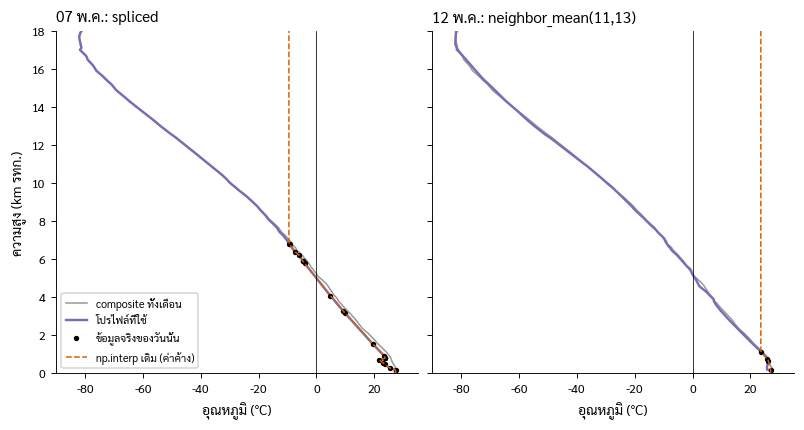

In [7]:
# รูป 2: ตัวอย่างการต่อเติมและค่าเฉลี่ยวันข้างเคียง เทียบกับผลของ np.interp แบบเดิม (ค่าคงที่เหนือยอด)
show = [summ.loc[summ["hid_profile_source"].str.startswith(k), "day"].iloc[0] for k in ("spliced", "neighbor")
        if summ["hid_profile_source"].str.startswith(k).any()]
fig, axs = plt.subplots(1, len(show), figsize=(3.6 * len(show), 3.8), sharey=True, layout="constrained", squeeze=False)
z = prof["height"].values
for ax, d in zip(axs[0], show):
    T_new = prof["temperature"].sel(day=d).values
    ax.plot(prof["composite_temperature"].values, z / 1000, color="0.6", lw=1, label="composite ทั้งเดือน")
    ax.plot(T_new, z / 1000, color="#7570b3", lw=1.6, label="โปรไฟล์ที่ใช้")
    if d in korat:
        q, _ = S.qc_profile(korat[d])
        ax.plot(q["temperature_C"], q["height_m"] / 1000, "o", ms=2.5, color="k", label="ข้อมูลจริงของวันนั้น")
        clamp = np.interp(z, q["height_m"], q["temperature_C"])            # สิ่งที่ add_temperature เดิมจะได้
        ax.plot(clamp, z / 1000, color="#d95f02", ls="--", lw=1, label="np.interp เดิม (ค่าค้าง)")
    ax.axvline(0, color="k", lw=0.5)
    ax.set_xlim(-90, 35); ax.set_ylim(0, 18); ax.set_xlabel("อุณหภูมิ (°C)")
    ax.set_title(f"{pd.Timestamp(d):%d พ.ค.}: {summ.set_index('day').loc[d, 'hid_profile_source']}", loc="left")
axs[0][0].set_ylabel("ความสูง (km รทก.)"); axs[0][0].legend(fontsize=7, loc="lower left")
M.savefig(fig, "ps_splice_examples", outdir=SND / "figures")
plt.show()

## 4. ดัชนีสภาพแวดล้อมรายวัน (เฉพาะ sounding จริงที่ครบ)

ใช้เป็นตัวแปรร่วมในบท 02 และ 05 (เช่น วันที่ CAPE หรือ DCAPE สูงมีพายุยาวกว่าหรือไม่) **ไม่คำนวณจากโปรไฟล์ต่อเติม** เพราะ CAPE ขึ้นกับความชื้นชั้นล่างและโปรไฟล์ทั้งคอลัมน์ของวันนั้น และข้อควรระวังคือ 00 UTC = 07 น. เป็นสภาพก่อนพายุตอนเช้า ไม่ใช่ CAPE สูงสุดของวัน

In [8]:
env_rows = []
for d in DAYS:
    if d in korat and summ.set_index("day").loc[d, "korat_quality"] == "full":
        q, _ = S.qc_profile(korat[d])
        env_rows.append({"day": d, **S.environment_indices(q)})
env = pd.DataFrame(env_rows)
env = summ[["day", "hid_profile_source", "z0C_m", "zm20C_m"]].merge(env, on="day", how="left")
env["phase"] = pd.cut(env["day"].dt.day, [0, 9, 20, 31], labels=[p["key"] for p in s["phases"]])
env.round(1)

,day,hid_profile_source,z0C_m,zm20C_m,SBCAPE_Jkg,SBCIN_Jkg,MLCAPE_Jkg,MLCIN_Jkg,MUCAPE_Jkg,LCL_hPa,PW_mm,DCAPE_Jkg,lapse_700_500_Ckm,shear_0_1km_ms,shear_0_6km_ms,mean_wind_0_6km_ms,mean_wind_0_6km_dir_to_deg,phase
0,2024-05-01,own,5650.6,8744.2,1498.9,-218.9,1304.1,-207.2,1498.9,900.5,44.6,1402.0,5.3,5.8,2.1,3.5,84.0,outbreak
1,2024-05-02,own,5379.0,8735.5,2032.4,-157.7,865.2,-167.6,2032.4,920.9,40.4,1459.2,5.6,4.2,4.0,0.6,25.9,outbreak
2,2024-05-03,own,5172.0,8516.0,1580.4,-192.2,1376.5,-165.1,1863.0,920.1,40.5,1453.9,5.7,2.7,3.8,2.5,140.4,outbreak
3,2024-05-04,own,4831.3,8483.3,304.0,-305.3,41.4,-298.5,836.6,903.8,45.7,1324.3,5.0,4.2,11.8,4.7,90.6,outbreak
4,2024-05-05,own,5291.2,8384.5,4133.7,-30.9,1432.5,-135.5,4133.7,956.6,53.6,1370.4,5.4,2.5,1.5,1.0,144.6,outbreak
5,2024-05-06,own,5047.3,8405.4,782.5,-286.5,1134.7,-127.9,2533.8,920.8,49.6,1384.3,5.7,2.4,2.5,1.4,37.8,outbreak
6,2024-05-07,spliced,5004.6,8698.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,outbreak
7,2024-05-08,spliced,5202.9,8407.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,outbreak
8,2024-05-09,own,5063.7,8643.6,2281.7,-94.0,842.0,-70.7,2281.7,957.1,56.3,1116.1,4.6,2.8,5.7,3.9,318.2,outbreak
9,2024-05-10,own,5252.6,8442.4,1738.0,-57.7,1502.7,-52.7,1738.0,935.9,61.2,698.4,4.9,1.1,3.8,2.7,327.9,late_pre


บันทึกรูป → /content/Teach_stormTracks_KKN_May2024_HID_doppler/data/sounding/figures/ps_environment_timeseries.png / .pdf


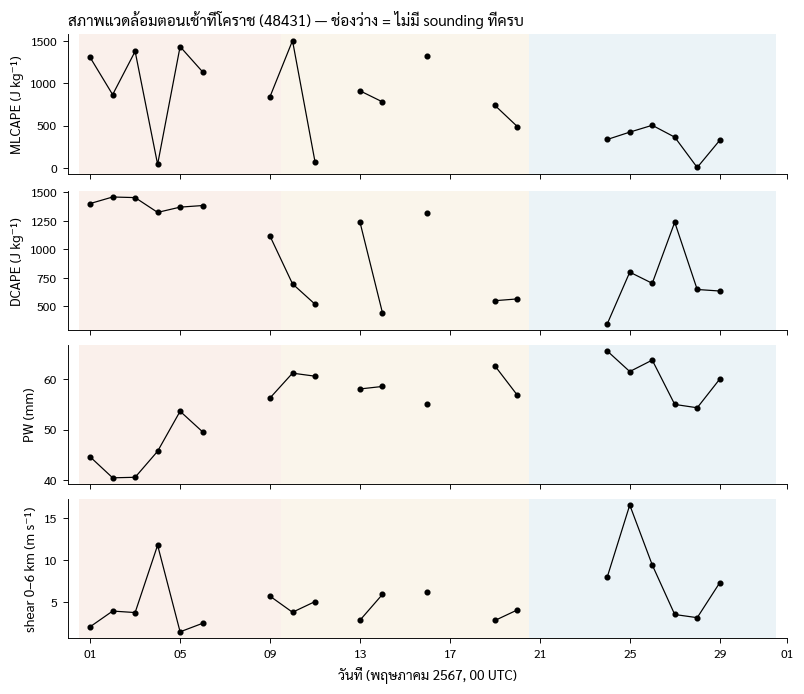

In [9]:
fig, axs = plt.subplots(4, 1, figsize=(7.2, 6.2), sharex=True, layout="constrained")
for ax, (col, lab) in zip(axs, [("MLCAPE_Jkg", "MLCAPE (J kg⁻¹)"), ("DCAPE_Jkg", "DCAPE (J kg⁻¹)"),
                                ("PW_mm", "PW (mm)"), ("shear_0_6km_ms", "shear 0–6 km (m s⁻¹)")]):
    for p in s["phases"]:
        ax.axvspan(pd.Timestamp(p["start"]) - pd.Timedelta(hours=12), pd.Timestamp(p["end"]) + pd.Timedelta(hours=12),
                   color=M.PHASE_COLORS[p["key"]], alpha=0.08, lw=0)
    ax.plot(env["day"], env[col], "o-", ms=3, color="k", lw=0.8)
    ax.set_ylabel(lab)
axs[-1].set_xlim(DAYS[0] - pd.Timedelta(days=1), DAYS[-1] + pd.Timedelta(days=1))
axs[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d")); axs[-1].set_xlabel("วันที่ (พฤษภาคม 2567, 00 UTC)")
axs[0].set_title("สภาพแวดล้อมตอนเช้าที่โคราช (48431) — ช่องว่าง = ไม่มี sounding ที่ครบ", loc="left")
M.savefig(fig, "ps_environment_timeseries", outdir=SND / "figures")
plt.show()

## 5. บันทึกผล

In [10]:
enc = {"temperature": {"zlib": True, "least_significant_digit": 2}, "dewpoint": {"zlib": True, "least_significant_digit": 2}}
prof_out = prof.copy(); prof_out["source"] = prof_out["source"].astype(str)
prof_out.to_netcdf(SND / "may2024_hid_profiles.nc", encoding=enc)
summ.to_csv(SND / "may2024_hid_profile_summary.csv", index=False)
qc.assign(flags=qc["flags"].apply(lambda f: ";".join(f))).to_csv(SND / "may2024_sounding_qc.csv", index=False)
env.to_csv(SND / "may2024_environment_daily.csv", index=False)
lev = []
for stn, src in (("48431", korat), ("48407", ubon)):
    for d, df in src.items():
        q, _ = S.qc_profile(df)
        lev.append(q.assign(station=stn, day=d, source=df.attrs.get("source", "")))
pd.concat(lev).to_csv(SND / "may2024_levels_qc.csv", index=False)
if OUT_ROOT.parent.exists():
    shutil.copytree(SND, OUT_ROOT / "sounding", dirs_exist_ok=True)
print("บันทึกใน", SND, ":", *sorted(p.name for p in SND.glob("*.*")), sep="\n  ")

บันทึกใน
  /content/Teach_stormTracks_KKN_May2024_HID_doppler/data/sounding
  :
  may2024_download_attempts.csv
  may2024_environment_daily.csv
  may2024_hid_profile_summary.csv
  may2024_hid_profiles.nc
  may2024_levels_qc.csv
  may2024_sounding_qc.csv


**ขั้นต่อไป:** commit โฟลเดอร์ `data/sounding/` แล้วรัน P2 ซึ่งจะอ่าน `may2024_hid_profiles.nc` โดยอัตโนมัติ

**อ้างอิง:** University of Wyoming Upper Air Archive; Bringi & Chandrasekar (2001) *Polarimetric Doppler Weather Radar*; Besic et al. (2016) *AMT* 9, 4425–4445